<a href="https://colab.research.google.com/github/CompOmics/lsabd-machine-learning-tutorials/blob/main/notebooks/3-real-life-regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression on real-life data

In the previous notebooks, we used clean or synthetic datasets. Real-life data are rarely that convenient: they contain missing values, special codes, columns you should not use, and targets that are hard to predict. In this notebook, we go through a complete machine learning workflow on real health survey data, from the raw table to a saved model. We will cover:

1. Exploring the data
2. Preparing the data
3. Starting simple: a linear regression model
4. Finding the best model with a grid search
5. Evaluating the final model and saving it

Your project will follow the same steps, so feel free to use this notebook as a template. Throughout the notebook, we refer back to notebooks 1 and 2 where a technique was introduced. There are also links to the relevant documentation for the functions and classes used. Click on the links and explore the documentation to deepen your understanding.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for our visualizations
sns.set_style("whitegrid")
sns.set_palette("deep")

## 1. Exploring the data

### Background

The [National Health and Nutrition Examination Survey (NHANES)](https://wwwn.cdc.gov/nchs/nhanes/) is a program of the US Centers for Disease Control and Prevention (CDC). Every two years, a representative sample of the US population is interviewed, physically examined, and asked to provide blood samples. The data are publicly available and widely used in medical research.

High blood pressure is one of the most important risk factors for cardiovascular disease, but many people do not know that their blood pressure is too high. In this notebook, we ask: **can we estimate a person's systolic blood pressure from other basic health information?**

Imagine a quick health check, for instance at a pharmacy or as part of a survey, that collects:

- general information about the person, such as age, gender and income;
- simple body measurements: weight, height, waist circumference and pulse;
- a few routine blood values, such as cholesterol;
- some lifestyle questions, such as smoking and time spent sitting.

The blood pressure itself is **not** measured, and we do not know whether the person has been diagnosed or treated for high blood pressure. Our model should estimate the blood pressure from the information above only, so that people with a likely high blood pressure can be advised to get it checked.

We prepared a table with a selection of columns from the [2017-2018 NHANES cycle](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?BeginYear=2017). It combines eight separate data files, merged on the participant ID. The values are exactly as published by the CDC. The table below describes each column; click on the data file to see its full documentation:

| Column | Description | Data file |
|--------|-------------|-----------|
| `SEQN` | Participant ID | [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) |
| `RIDAGEYR` | Age in years (80 = 80 years or older) | [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) |
| `RIAGENDR` | Gender (1 = male, 2 = female) | [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) |
| `RIDRETH3` | Ethnic background (category code 1-7) | [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) |
| `DMDEDUC2` | Education level of adults 20+ (category code 1-5; 7 = refused, 9 = don't know) | [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) |
| `INDFMPIR` | Ratio of family income to the poverty threshold (5 = 5 or more) | [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) |
| `BMXWT` | Weight (kg) | [BMX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BMX_J.htm) |
| `BMXHT` | Height (cm) | [BMX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BMX_J.htm) |
| `BMXBMI` | Body mass index (kg/m²) | [BMX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BMX_J.htm) |
| `BMXWAIST` | Waist circumference (cm) | [BMX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BMX_J.htm) |
| `BPXPLS` | Pulse (beats per minute) | [BPX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPX_J.htm) |
| `BPXSY1`, `BPXSY2`, `BPXSY3` | Systolic blood pressure, readings 1 to 3 (mmHg) | [BPX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPX_J.htm) |
| `BPXDI1`, `BPXDI2`, `BPXDI3` | Diastolic blood pressure, readings 1 to 3 (mmHg) | [BPX_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPX_J.htm) |
| `BPQ020` | Ever told by a doctor that you have high blood pressure (1 = yes, 2 = no, 9 = don't know) | [BPQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPQ_J.htm) |
| `BPQ050A` | Now taking prescribed medicine for high blood pressure (1 = yes, 2 = no); only asked to participants who were told to take such medicine | [BPQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPQ_J.htm) |
| `LBXTC` | Total cholesterol in the blood (mg/dL) | [TCHOL_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/TCHOL_J.htm) |
| `LBXGH` | Glycohemoglobin (HbA1c, %), a long-term measure of blood sugar | [GHB_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/GHB_J.htm) |
| `PAD680` | Minutes spent sitting on a typical day (7777 = refused, 9999 = don't know) | [PAQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/PAQ_J.htm) |
| `SMQ020` | Smoked at least 100 cigarettes in life (1 = yes, 2 = no) | [SMQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/SMQ_J.htm) |

Note the special codes, such as 7777 for "refused". These are typical for survey data, and we will need to deal with them.

*Question: Is predicting the systolic blood pressure a classification or a regression task? Why?*

*Answer: It is a regression task: the target, the systolic blood pressure in millimeters of mercury (mmHg), is a continuous value, not a class label.*

### Loading the data

As in notebook 1, we use the pandas [`read_csv()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) function to load the table:

In [2]:
data = pd.read_csv(
    "https://github.com/CompOmics/lsabd-machine-learning-tutorials/raw/refs/heads/main/data/nhanes_2017_2018.csv"
)
data

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,DMDEDUC2,INDFMPIR,BMXWT,BMXHT,BMXBMI,BMXWAIST,...,BPXSY3,BPXDI1,BPXDI2,BPXDI3,BPQ020,BPQ050A,LBXTC,LBXGH,PAD680,SMQ020
0,93703,2.0,2.0,6.0,NaN,5.00,13.7,88.6,17.5,48.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704,2.0,1.0,3.0,NaN,5.00,13.9,94.2,15.7,50.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,93705,66.0,2.0,4.0,2.0,0.82,79.5,158.3,31.7,101.8,...,202.0,NaN,NaN,62.0,1.0,1.0,157.0,6.2,300.0,1.0
3,93706,18.0,1.0,6.0,NaN,NaN,66.3,175.7,21.5,79.3,...,108.0,74.0,70.0,76.0,2.0,NaN,148.0,5.2,240.0,2.0
4,93707,13.0,1.0,7.0,NaN,1.88,45.4,158.4,18.1,64.1,...,128.0,38.0,46.0,58.0,NaN,NaN,189.0,5.6,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9249,102952,70.0,2.0,6.0,3.0,0.95,49.0,156.5,20.0,82.2,...,140.0,74.0,78.0,68.0,2.0,NaN,119.0,7.4,120.0,2.0
9250,102953,42.0,1.0,1.0,3.0,NaN,97.4,164.9,35.8,114.8,...,116.0,76.0,76.0,74.0,2.0,NaN,182.0,5.9,360.0,1.0
9251,102954,41.0,2.0,4.0,5.0,1.18,69.1,162.6,26.1,86.4,...,114.0,66.0,72.0,74.0,2.0,NaN,172.0,5.2,600.0,2.0
9252,102955,14.0,2.0,4.0,NaN,2.24,111.9,156.6,45.6,113.5,...,114.0,62.0,60.0,64.0,NaN,NaN,150.0,5.5,NaN,NaN


*Question: How many samples (rows) and columns does the table contain? Compared to the number of samples, is the number of columns large? Think back to the "curse of dimensionality" in notebook 2.*

*Answer: The table contains 9,254 rows and 23 columns. Even though not all rows and columns will be usable, there are many more samples than columns. This is the opposite of the typical -omics situation described in notebook 2, so the curse of dimensionality is not a concern here.*

### Exploring the columns

Not every column in a table is a feature. Before training a model, decide for each column whether it is:

1. the **target** that we want to predict,
2. a useful **feature**, or
3. a column that should be **removed**, such as an identifier or a column that causes data leakage.

**Data leakage** occurs when the features contain information about the target that would not be available when the model is used in practice. In notebook 1, we already saw one form of leakage: fitting a scaler on the full dataset, so that information from the test set leaks into training. Here, the leakage would come from the columns themselves. A model trained with leaky features looks very good during evaluation, but is useless in practice. Always ask yourself: *would I have this information at the moment I want to make a prediction?*

*Question: Think back to the health check described in the background: the blood pressure is not measured, and we do not know about any diagnosis or treatment. Using the column descriptions above, which columns contain the target? Which columns would leak information about the target? Which column is an identifier?*

*Answer: The systolic blood pressure readings `BPXSY1`, `BPXSY2` and `BPXSY3` form the target. The diastolic readings `BPXDI1`, `BPXDI2` and `BPXDI3` are measured with the same blood pressure cuff at the same moment: if we had them, we would also have the systolic blood pressure. `BPQ020` (told you have high blood pressure) and `BPQ050A` (taking blood pressure medication) are consequences of a high blood pressure, so they directly reveal the target. `SEQN` is an identifier: it contains no information about the participant. The pulse (`BPXPLS`) is also measured during the blood pressure examination, but a pulse can easily be measured without a blood pressure cuff, so we can keep it as a feature.*

Some columns store categories as numbers. For instance, `RIDRETH3` uses the codes 1 to 7 for different ethnic backgrounds. A model would treat these codes as measurements: code 6 would be "more" than code 3, which is meaningless. As in notebook 1, we leave such categorical features out until you have gained more machine learning experience. Columns with only two categories, such as `RIAGENDR` (1 = male, 2 = female) and `SMQ020` (1 = yes, 2 = no), are an exception: with only two values, a model can use them as numbers without problems.

Based on this, we define which columns are features, which form the target, and which columns leak information about the target:

In [3]:
feature_columns = [
    "RIDAGEYR",  # age
    "RIAGENDR",  # gender
    "INDFMPIR",  # income to poverty ratio
    "BMXWT",  # weight
    "BMXHT",  # height
    "BMXBMI",  # body mass index
    "BMXWAIST",  # waist circumference
    "BPXPLS",  # pulse
    "LBXTC",  # total cholesterol
    "LBXGH",  # glycohemoglobin
    "PAD680",  # minutes spent sitting
    "SMQ020",  # smoked at least 100 cigarettes
]
target_columns = ["BPXSY1", "BPXSY2", "BPXSY3"]  # systolic blood pressure readings
leaky_columns = ["BPXDI1", "BPXDI2", "BPXDI3", "BPQ020", "BPQ050A"]

### Exploring the features

First, let's check the data types of the features with the [`dtypes`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dtypes.html) property, as in notebook 1:

In [4]:
data[feature_columns].dtypes

RIDAGEYR    float64
RIAGENDR    float64
INDFMPIR    float64
BMXWT       float64
BMXHT       float64
BMXBMI      float64
BMXWAIST    float64
BPXPLS      float64
LBXTC       float64
LBXGH       float64
PAD680      float64
SMQ020      float64
dtype: object

All features are numerical (`float64`, decimal numbers). Note that even yes/no columns are stored as decimal numbers: pandas uses `float64` for any numeric column that contains missing values.

Next, let's look for **special codes**. They look like normal numbers, but they are not measurements. The [`describe()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html) method from notebook 1 is a quick way to spot them:

In [5]:
data[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,9254.0,34.334234,25.500280,0.0,11.00,31.00,58.00,80.0
RIAGENDR,9254.0,1.507564,0.499970,1.0,1.00,2.00,2.00,2.0
INDFMPIR,8023.0,2.375490,1.600291,0.0,1.04,1.92,3.69,5.0
BMXWT,8580.0,65.138508,32.890754,3.2,43.10,67.75,85.60,242.6
BMXHT,8016.0,156.593401,22.257858,78.3,151.40,161.90,171.20,197.7
BMXBMI,8005.0,26.577502,8.260724,12.3,20.40,25.80,31.30,86.2
BMXWAIST,7601.0,89.928851,22.805093,40.0,73.90,91.20,105.30,169.5
BPXPLS,6742.0,73.749926,12.380546,34.0,66.00,72.00,82.00,136.0
LBXTC,6738.0,179.894627,40.602248,76.0,151.00,176.00,204.00,446.0
LBXGH,6045.0,5.769562,1.037838,3.8,5.20,5.50,5.90,16.2


*Question: Look at the minimum and maximum values. Which feature contains special codes? Are there other suspicious values?*

*Answer: `PAD680` (minutes spent sitting) has a maximum of 9999, which is the special code for "don't know" (there is no day with 9999 minutes). The maximum of `RIDAGEYR` (80) and `INDFMPIR` (5) are not errors, but top-coded values: they mean "80 or older" and "5 or more". The other features have plausible ranges.*

A histogram makes such codes easy to spot: they show up as a separate group of values, far away from the rest of the distribution. Let's plot the `PAD680` column with the Seaborn [`histplot`](https://seaborn.pydata.org/generated/seaborn.histplot.html) function, as in notebook 1. Because only a few participants have a special code, we use a logarithmic scale for the counts on the y-axis, so that small bars remain visible:

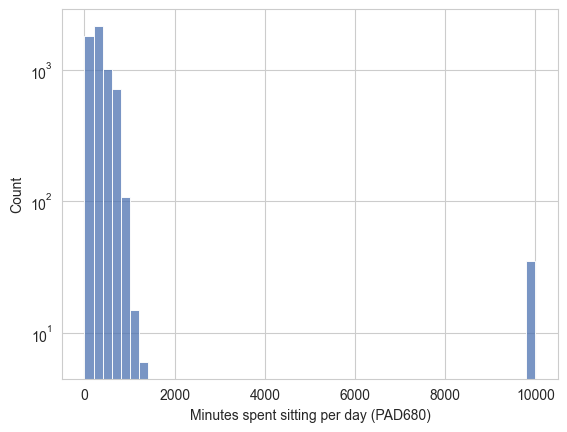

In [6]:
sns.histplot(data=data, x="PAD680", bins=50)
plt.yscale("log")
plt.xlabel("Minutes spent sitting per day (PAD680)")
plt.show()

The real values range from 0 to about 1,300 minutes (a day has 1,440 minutes), while a separate bar sits at 9999: the code for "don't know". If we left these codes in, the model would treat them as people who sit for almost a week per day.

*Task: Replace the special codes 7777 and 9999 in the `PAD680` column with missing values (`np.nan`). Use the pandas [`replace()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.replace.html) method, which takes a list of values to replace and the new value: `data["PAD680"] = data["PAD680"].replace([..., ...], np.nan)`. Then, plot the histogram again (you can copy the code from the previous cell) to check that the special codes are gone.*

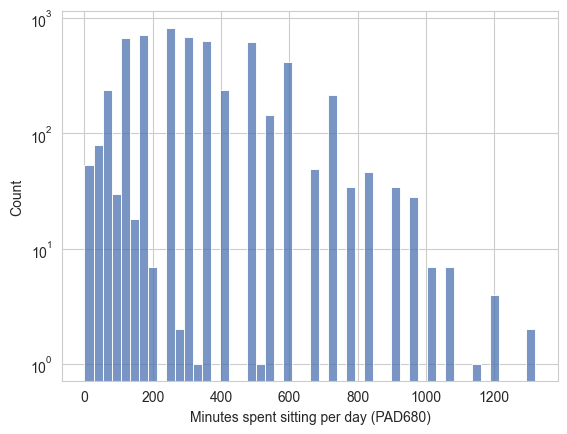

In [7]:
# Replace the special codes 7777 and 9999 in the PAD680 column with np.nan
# Then, plot the histogram again to check that the special codes are gone

data["PAD680"] = data["PAD680"].replace([7777, 9999], np.nan)

sns.histplot(data=data, x="PAD680", bins=50)
plt.yscale("log")
plt.xlabel("Minutes spent sitting per day (PAD680)")
plt.show()

Now, let's check for missing values with the [`isnull()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.isnull.html) method, as in notebook 1:

In [8]:
data[feature_columns].isnull().sum()

RIDAGEYR       0
RIAGENDR       0
INDFMPIR    1231
BMXWT        674
BMXHT       1238
BMXBMI      1249
BMXWAIST    1653
BPXPLS      2512
LBXTC       2516
LBXGH       3209
PAD680      3443
SMQ020      3398
dtype: int64

Many values are missing, and for different reasons. Some questions are only asked to adults: `PAD680` and `SMQ020`, for example, are only asked to participants of 18 years or older. Other values are missing because a participant did not take part in the physical examination or did not provide a blood sample. We will deal with the missing values in the data preparation section.

Finally, let's look at the distributions of the features.

*Task: Visualize the distributions of the features with box plots, as in notebook 1. Use the Seaborn [`boxplot`](https://seaborn.pydata.org/generated/seaborn.boxplot.html) function on the melted feature table: `sns.boxplot(data=data[feature_columns].melt(), x="value", y="variable")`.*

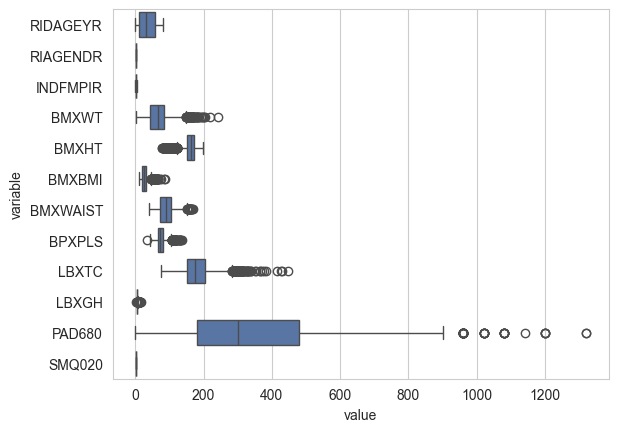

In [9]:
# Create box plots of all features, as in notebook 1

sns.boxplot(data=data[feature_columns].melt(), x="value", y="variable")
plt.show()

*Question: Are the features on similar scales? Will we need to scale them?*

*Answer: No, the scales differ a lot. `PAD680` ranges from 0 to 1,320 minutes and `LBXTC` from about 76 to 446 mg/dL, while `RIAGENDR` and `SMQ020` only take the values 1 and 2, and `LBXGH` ranges from about 3.8 to 16.2%. We will therefore scale the features with a `StandardScaler` as part of the pipeline.*

### Exploring the target

Each participant had their blood pressure measured up to three times. As is common in practice, we use the average of the available readings as the target. The pandas [`mean()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.mean.html) method with `axis=1` computes the average per row (instead of per column) and skips missing readings.

*Task: Compute the average systolic blood pressure per participant: `data[target_columns].mean(axis=1)`, and store it in a new column `data["systolic_bp"]`. Then, visualize its distribution with the Seaborn [`histplot`](https://seaborn.pydata.org/generated/seaborn.histplot.html) function, as in notebook 1. Add an x-axis label with `plt.xlabel()`.*

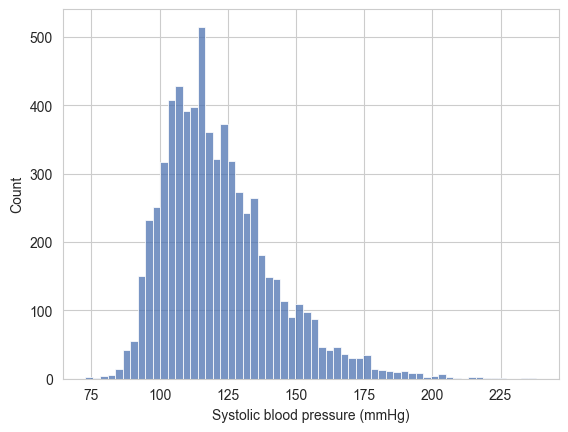

In [10]:
# Compute the average systolic blood pressure per participant and store it in data["systolic_bp"]
# Then, visualize its distribution with a histogram

data["systolic_bp"] = data[target_columns].mean(axis=1)

sns.histplot(data=data, x="systolic_bp")
plt.xlabel("Systolic blood pressure (mmHg)")
plt.show()

In [11]:
print(f"Participants without a blood pressure reading: {data['systolic_bp'].isnull().sum()}")
data["systolic_bp"].describe()

Participants without a blood pressure reading: 2540


count    6714.000000
mean      121.693178
std        20.359703
min        72.666667
25%       106.666667
50%       118.000000
75%       132.666667
max       238.000000
Name: systolic_bp, dtype: float64

*Question: Describe the distribution of the target. Are there participants without a target value?*

*Answer: Most participants have a systolic blood pressure between about 107 and 133 mmHg (the 25th and 75th percentiles), with a mean of 122 mmHg. The distribution has a long tail to the right: a small group of participants has a very high blood pressure, up to 238 mmHg. 2,540 participants have no blood pressure reading at all, for instance because blood pressure was not measured in young children or because they did not take part in the examination.*

## 2. Preparing the data

The goal of data preparation is to go from the raw table to a clean table of features and a target, containing only usable samples.

### Selecting samples

Not every row is a useful sample:

- **Children:** blood pressure in children follows different norms, and many questions are only asked to adults. We therefore only keep adults (18 years or older).
- **Missing target:** a sample without a target value cannot be used for training or evaluation.
- **Missing features:** most scikit-learn models cannot handle missing values.

Let's apply these steps one by one, and keep track of how many samples remain. The pandas [`dropna()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dropna.html) method removes rows with missing values; with the `subset` parameter, it only looks at the given columns:

In [12]:
print(f"All participants: {len(data)}")

# Keep only adults
adults = data[data["RIDAGEYR"] >= 18]
print(f"Adults: {len(adults)}")

# Remove samples without a target value
adults_with_target = adults.dropna(subset=["systolic_bp"])
print(f"Adults with a target value: {len(adults_with_target)}")

# Remove samples with missing values in any of the features
complete_data = adults_with_target.dropna(subset=feature_columns)
print(f"Adults with a target value and all features: {len(complete_data)}")

All participants: 9254
Adults: 5856
Adults with a target value: 5247
Adults with a target value and all features: 4127


Removing all samples with a missing feature costs quite a few samples. Let's see which features are responsible:

In [13]:
adults_with_target[feature_columns].isnull().sum()

RIDAGEYR      0
RIAGENDR      0
INDFMPIR    669
BMXWT        62
BMXHT        63
BMXBMI       71
BMXWAIST    252
BPXPLS        0
LBXTC       322
LBXGH       240
PAD680       38
SMQ020        0
dtype: int64

*Question: Which feature is responsible for most of the removed samples? Would you rather remove that feature, or the samples in which it is missing? What are the advantages and disadvantages of both options?*

*Answer: The income to poverty ratio (`INDFMPIR`) is missing for 669 adults, more than any other feature. Removing the feature would keep these samples, but we would lose the information that income carries about health. Removing the samples keeps the feature, but leaves less data to train on, and the remaining participants might be less representative: people who do not report their income might differ from those who do. There is no single right answer. Here, we have enough samples to remove them. A third option, which is out of scope for this course, is to fill in (impute) the missing values, as described in the [Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html) section of the Scikit-learn User Guide.*

### Selecting features and target

Now, we can separate the features from the target, as in notebook 1:

In [14]:
features = complete_data[feature_columns]
targets = complete_data["systolic_bp"]

print(f"Features: {features.shape}")
print(f"Targets: {targets.shape}")

Features: (4127, 12)
Targets: (4127,)


### Splitting the data

To build and evaluate a model honestly, we split the data into three sets, each with its own role:

- The **training set** is used to train the models.
- The **validation set** is used to evaluate and compare models while we are still building them, for instance to decide which model works best.
- The **test set** is put aside and is **only** used at the very end, to evaluate the final model once.

Why do we need both a validation and a test set? Every time we use a set to make a decision, such as choosing one model over another, that set influences the final model. If we chose the model based on the test set, we would pick the model that happens to work best on those particular test samples, and the test score would be too optimistic. The test set must therefore stay unseen until the very end, and we use the validation set for all decisions along the way.

We create the three sets with two consecutive splits: first, we split off the test set; then, we split the remaining data into a training and a validation set. We use 60% of the data for training, 20% for validation, and 20% for testing.

*Task: Split the data into training, validation, and test sets with the [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function, as in notebook 1, in two steps:*

1. *Split `features` and `targets` with `test_size=0.2` and `random_state=42`. Store the results in the variables `train_val_features`, `test_features`, `train_val_targets`, and `test_targets`.*
2. *Split `train_val_features` and `train_val_targets` again, now with `test_size=0.25` (25% of the remaining 80% is 20% of all data) and `random_state=42`. Store the results in the variables `train_features`, `val_features`, `train_targets`, and `val_targets`.*

*Note that we cannot stratify a continuous target, as explained in the regression section of notebook 1.*

In [15]:
# Step 1: split off the test set (20% of all data, random_state=42)
# Step 2: split the remaining data into training and validation sets (test_size=0.25, random_state=42)

from sklearn.model_selection import train_test_split

train_val_features, test_features, train_val_targets, test_targets = train_test_split(
    features, targets, test_size=0.2, random_state=42
)
train_features, val_features, train_targets, val_targets = train_test_split(
    train_val_features, train_val_targets, test_size=0.25, random_state=42
)

print(f"Training set: {train_features.shape}")
print(f"Validation set: {val_features.shape}")
print(f"Testing set: {test_features.shape}")

Training set: (2475, 12)
Validation set: (826, 12)
Testing set: (826, 12)


## 3. Starting simple: a linear regression model

It is good practice to start with a simple model. It gives a baseline: any more complex model should do better to be worth it. As in notebook 1, we combine the scaling and the model in a [`Pipeline`](https://scikit-learn.org/stable/modules/compose.html#pipeline-chaining-estimators), so that the scaler is always fit on the training data only.

*Task: Create a pipeline with a [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) and a [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) model with the `make_pipeline` function, as in the regression example at the end of notebook 1. Store it in the variable `linear_pipeline`. Then, fit the pipeline on the training data with its `fit()` method, and use its `predict()` method to make predictions for both the training and the validation features. Store the predictions in the variables `train_predictions` and `val_predictions`.*

In [16]:
# Create a pipeline with a StandardScaler and a LinearRegression model, and store it in linear_pipeline
# Fit it on the training data, then predict the training and validation features
# Store the predictions in train_predictions and val_predictions

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

linear_pipeline = make_pipeline(StandardScaler(), LinearRegression())
linear_pipeline.fit(train_features, train_targets)

train_predictions = linear_pipeline.predict(train_features)
val_predictions = linear_pipeline.predict(val_features)

Let's calculate the R² and the mean absolute error (MAE) with the [`r2_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html) and [`mean_absolute_error`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html) functions, as in notebook 1, for both the training and the validation set. As in notebook 2, comparing both tells us whether the model overfits. We also plot the predicted against the true values:

Training R²:   0.26
Validation R²: 0.29
Training MAE:   12.6 mmHg
Validation MAE: 12.7 mmHg


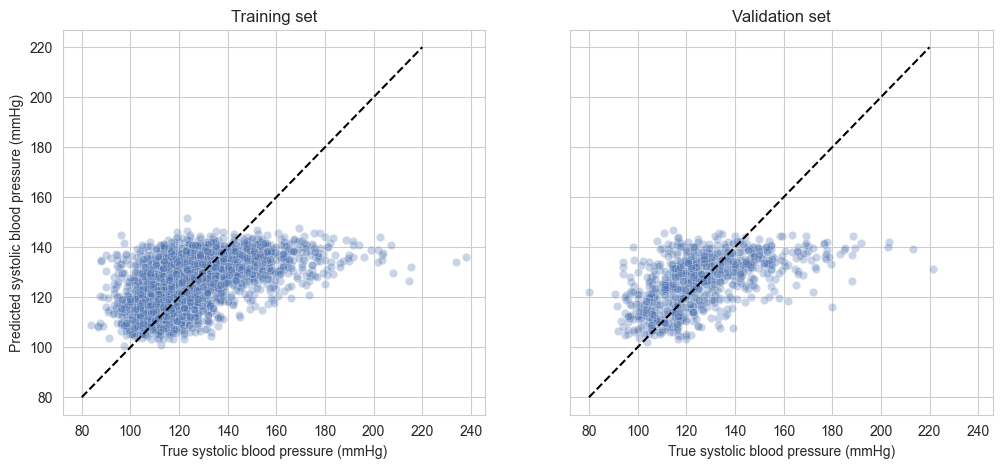

In [17]:
from sklearn.metrics import mean_absolute_error, r2_score

print(f"Training R²:   {r2_score(train_targets, train_predictions):.2f}")
print(f"Validation R²: {r2_score(val_targets, val_predictions):.2f}")
print(f"Training MAE:   {mean_absolute_error(train_targets, train_predictions):.1f} mmHg")
print(f"Validation MAE: {mean_absolute_error(val_targets, val_predictions):.1f} mmHg")

fig, axes = plt.subplots(figsize=(12, 5), ncols=2, sharex=True, sharey=True)
for ax, true_values, predictions, title in zip(
    axes,
    [train_targets, val_targets],
    [train_predictions, val_predictions],
    ["Training set", "Validation set"],
):
    sns.scatterplot(x=true_values, y=predictions, alpha=0.3, ax=ax)
    ax.plot([80, 220], [80, 220], "k--")  # diagonal: perfect predictions
    ax.set_title(title)
    ax.set_xlabel("True systolic blood pressure (mmHg)")
    ax.set_ylabel("Predicted systolic blood pressure (mmHg)")
plt.show()

Note that the cloud of points is much flatter than the diagonal. When the features explain only a small part of the target, the model "hedges its bets" and predicts values close to the average blood pressure for everyone. As a result, high blood pressures are systematically underestimated and low blood pressures overestimated.

*Question: How well does the linear regression model perform? Is it overfitting?*

*Answer: The model explains only about a quarter of the variance in blood pressure (validation R² of 0.29), with a typical error (MAE) of about 13 mmHg. The training and validation scores are almost the same, so the model is not overfitting. Rather, the features do not contain enough information to predict the blood pressure accurately. We will come back to this at the end of the notebook.*

### What if we had kept the leaky columns?

To see why leakage matters, let's train the same model with two leaky columns added as features: the average diastolic blood pressure, and whether the participant was ever told they have high blood pressure (`BPQ020`, where we first replace the code 9 for "don't know" with a missing value). We train on the training samples and evaluate on the validation samples, as before.

Validation R² with leaky features: 0.49

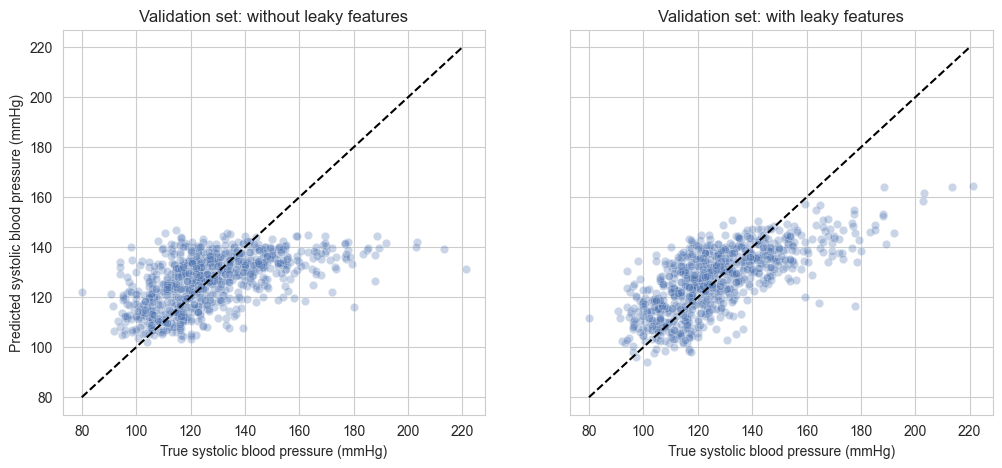

In [18]:
leaky_feature_columns = feature_columns + ["diastolic_bp", "BPQ020"]

leaky_data = complete_data.copy()
leaky_data["diastolic_bp"] = leaky_data[["BPXDI1", "BPXDI2", "BPXDI3"]].mean(axis=1)
leaky_data["BPQ020"] = leaky_data["BPQ020"].replace(9, np.nan)
leaky_data = leaky_data.dropna(subset=["diastolic_bp", "BPQ020"])

# Use the same training and validation samples as before (the test set stays untouched)
leaky_train = leaky_data[leaky_data.index.isin(train_features.index)]
leaky_val = leaky_data[leaky_data.index.isin(val_features.index)]

leaky_pipeline = make_pipeline(StandardScaler(), LinearRegression())
leaky_pipeline.fit(leaky_train[leaky_feature_columns], leaky_train["systolic_bp"])
leaky_val_predictions = leaky_pipeline.predict(leaky_val[leaky_feature_columns])

print(f"Validation R² with leaky features: {r2_score(leaky_val['systolic_bp'], leaky_val_predictions):.2f}")

# Compare the validation predictions without and with the leaky features
fig, axes = plt.subplots(figsize=(12, 5), ncols=2, sharex=True, sharey=True)
for ax, true_values, predictions, title in zip(
    axes,
    [val_targets, leaky_val["systolic_bp"]],
    [val_predictions, leaky_val_predictions],
    ["Validation set: without leaky features", "Validation set: with leaky features"],
):
    sns.scatterplot(x=true_values, y=predictions, alpha=0.3, ax=ax)
    ax.plot([80, 220], [80, 220], "k--")  # diagonal: perfect predictions
    ax.set_title(title)
    ax.set_xlabel("True systolic blood pressure (mmHg)")
    ax.set_ylabel("Predicted systolic blood pressure (mmHg)")
plt.show()

*Question: The score went up considerably. Why is this score misleading?*

*Answer: The validation R² increases from 0.29 to 0.49, but only because the model now uses information that is only available after measuring the blood pressure (the diastolic blood pressure) or after a diagnosis of high blood pressure. In the health check we described, this information is not available, and if we had it, we would not need the model. In practice, the model would perform much worse than this score suggests.*

## 4. Finding the best model

Can a different model, or different model settings, do better than the linear regression? In this section, we compare a regularized linear model with a random forest, a model you have not seen before.

### Random forests

In notebook 2, we saw that a single decision tree easily overfits: it has a low bias but a high variance. A [random forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html) reduces this variance by combining many decision trees. Each tree is trained on a random sample of the training data, and only considers a random subset of the features at each split. As a result, every tree is slightly different and makes different mistakes. The forest averages the predictions of all trees, so that these mistakes partly cancel out. The `max_depth` parameter still limits the complexity of each tree, just like for the single decision tree in notebook 2.

### Comparing many models: grid search with cross-validation

Settings such as the maximum tree depth or the regularization strength are called **hyperparameters**: they are chosen before training, rather than learned from the data. To find the best model, we want to try many combinations of models and hyperparameter values, and compare them. In notebook 2, we did this in a loop and compared the training and test scores. Here, we keep the test set aside, so we need another way to compare the models.

We could use the validation set from section 2. However, the validation score depends on which samples happen to end up in the validation set. To see how much, let's repeat the training and validation split from section 2 a few times with a different `random_state`, and calculate the validation R² of the linear model each time:

In [19]:
for seed in range(5):
    split_train_features, split_val_features, split_train_targets, split_val_targets = train_test_split(
        train_val_features, train_val_targets, test_size=0.25, random_state=seed
    )
    linear_pipeline.fit(split_train_features, split_train_targets)
    split_val_r2 = r2_score(split_val_targets, linear_pipeline.predict(split_val_features))
    print(f"Split with random_state={seed}: validation R² = {split_val_r2:.2f}")

Split with random_state=0: validation R² = 0.28
Split with random_state=1: validation R² = 0.25
Split with random_state=2: validation R² = 0.31
Split with random_state=3: validation R² = 0.20
Split with random_state=4: validation R² = 0.26


Exactly the same model gets a different validation score depending on the random split. When we compare models whose scores differ by only a few hundredths, a single validation set could therefore point us to the wrong model, just by chance.

#### Cross-validation

**Cross-validation** solves this problem by repeating the split in a systematic way, and averaging the results:

1. The training data are divided into *k* equal parts, called **folds**. A common choice is *k* = 5.
2. The model is trained *k* times. Each time, one fold is held out as validation set, and the model is trained on the other *k* - 1 folds.
3. Each trained model is evaluated on its held-out fold, giving *k* validation scores.
4. The final score is the average of the *k* validation scores. Their spread (standard deviation) shows how much the score depends on the data split.

With *k* = 5, the rounds look as follows:

| | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| Round 1 | **validation** | train | train | train | train |
| Round 2 | train | **validation** | train | train | train |
| Round 3 | train | train | **validation** | train | train |
| Round 4 | train | train | train | **validation** | train |
| Round 5 | train | train | train | train | **validation** |

Every sample is used for validation exactly once, and for training *k* - 1 times. The average over five validation folds is much less dependent on chance than a single validation score. The price is that the model has to be trained *k* times. The figure below, from the [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) section of the Scikit-learn User Guide, shows the same idea. Note that the test set stays aside: cross-validation only happens within the training data.

![Cross-validation](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)

Because the scaler is part of the pipeline, it is fit again in every round, on the training folds only. As explained in notebook 1, fitting the scaler on all data would leak information from the validation fold into the training.

#### Grid search

A **grid search** combines all of this: it tries every combination of the given hyperparameter values, evaluates each combination with cross-validation on the training set, and selects the combination with the best average validation score. Finally, it retrains the best model on the full training set. Scikit-learn provides the [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) class for this. The figure below, from the [Tuning the hyper-parameters of an estimator](https://scikit-learn.org/stable/modules/grid_search.html) section of the Scikit-learn User Guide, summarizes the workflow:

![Grid search workflow](https://scikit-learn.org/stable/_images/grid_search_workflow.png)

We compare two types of models:

- **Ridge regression**: linear regression with L2 regularization, as in notebook 2. We try several values of the regularization strength `alpha`. A small `alpha` gives almost the same model as plain linear regression.
- **Random forest**: we try several values of the maximum tree depth `max_depth`. The value `None` means no limit.

To let the grid search swap models, we build the pipeline with the [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) class instead of `make_pipeline`, so that we can give each step a name. The grid then refers to a parameter of a step with the step name, two underscores, and the parameter name: `model__alpha` is the `alpha` parameter of the step called `model`. With `return_train_score=True`, the grid search also reports the scores on the training folds, so that we can detect overfitting, as in notebook 2.

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# A pipeline with named steps; the model step will be replaced by the grid search
pipeline = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])

# The grid: a list with one dictionary per type of model
param_grid = [
    {
        "model": [Ridge()],
        "model__alpha": [0.1, 1, 10, 100, 1000],
    },
    {
        "model": [RandomForestRegressor(n_estimators=100, random_state=42)],
        "model__max_depth": [2, 4, 6, 8, 12, None],
    },
]

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,  # 5-fold cross-validation, as before
    scoring="r2",
    return_train_score=True,
    n_jobs=-1,  # use all available processor cores to speed things up
)
grid_search.fit(train_features, train_targets)

print(f"Best settings: {grid_search.best_params_}")
print(f"Best cross-validated R²: {grid_search.best_score_:.3f}")

Best settings: {'model': RandomForestRegressor(random_state=42), 'model__max_depth': 6}
Best cross-validated R²: 0.256


The `cv_results_` attribute contains the scores of all combinations. Let's put the most important information in a table. Note that scikit-learn calls the held-out fold the "test" fold: `mean_test_score` is the average cross-validated score, **not** the score on our test set, which we keep untouched.

In [21]:
results = pd.DataFrame(
    {
        "model": [type(params["model"]).__name__ for params in grid_search.cv_results_["params"]],
        "alpha": [params.get("model__alpha", "") for params in grid_search.cv_results_["params"]],
        "max_depth": [params.get("model__max_depth", "") for params in grid_search.cv_results_["params"]],
        "training R²": grid_search.cv_results_["mean_train_score"],
        "cross-validated R²": grid_search.cv_results_["mean_test_score"],
        "spread (std)": grid_search.cv_results_["std_test_score"],
    }
)
results.round(3)

,model,alpha,max_depth,training R²,cross-validated R²,spread (std)
0,Ridge,0.1,,0.261,0.247,0.031
1,Ridge,1,,0.261,0.247,0.031
2,Ridge,10,,0.261,0.247,0.030
3,Ridge,100,,0.259,0.247,0.027
4,Ridge,1000,,0.235,0.226,0.019
5,RandomForestRegressor,,2,0.247,0.220,0.044
6,RandomForestRegressor,,4,0.345,0.255,0.036
7,RandomForestRegressor,,6,0.465,0.256,0.036
8,RandomForestRegressor,,8,0.596,0.249,0.035
9,RandomForestRegressor,,12,0.794,0.232,0.036


As in notebook 2, let's plot the training and cross-validated scores of the random forest against the maximum tree depth, and compare them with the best Ridge model:

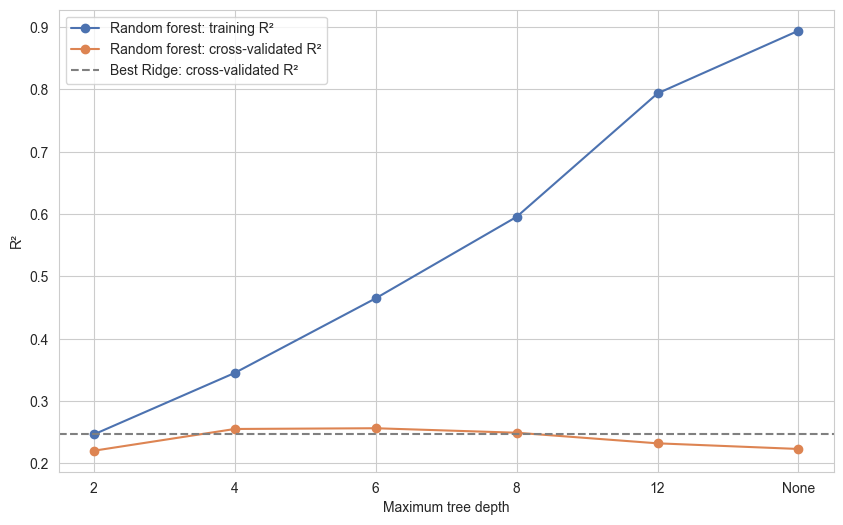

In [22]:
forest_results = results[results["model"] == "RandomForestRegressor"]
depth_labels = forest_results["max_depth"].astype(str)  # as text, so that None can be shown too
best_ridge_score = results[results["model"] == "Ridge"]["cross-validated R²"].max()

plt.figure(figsize=(10, 6))
plt.plot(depth_labels, forest_results["training R²"], "o-", label="Random forest: training R²")
plt.plot(depth_labels, forest_results["cross-validated R²"], "o-", label="Random forest: cross-validated R²")
plt.axhline(best_ridge_score, color="grey", linestyle="--", label="Best Ridge: cross-validated R²")
plt.xlabel("Maximum tree depth")
plt.ylabel("R²")
plt.legend()
plt.show()

*Question: Which model and settings give the best cross-validated R²? How much better is it than the linear models?*

*Answer: The random forest with a maximum depth of 6 gives the best cross-validated R² (0.26). This is only slightly better than the best Ridge model (0.25): the more complex model gains little. The difference is even smaller than the spread of the scores over the folds (a standard deviation of about 0.03), so we cannot be sure that the random forest is truly better.*

*Question: At which depth does the random forest start to overfit? How can you tell?*

*Answer: From a depth of about 6 onwards, the training R² keeps increasing (up to 0.89 without a depth limit), while the cross-validated R² no longer improves and even decreases. The growing gap between training and cross-validated performance is the sign of overfitting, as in notebook 2: deep trees start to memorize the noise in the training data. Very shallow trees (depth 2) have a lower score on both, which is a sign of underfitting.*

*Question: Why does the regularization strength of the Ridge model hardly matter here, unlike in notebook 2?*

*Answer: The training set contains about 2,500 samples for only 12 features. With so many samples per feature, a linear model has little room to overfit, so there is little for regularization to correct. In notebook 2, the regression dataset had only 80 samples for 100 features, which made regularization essential. Only very strong regularization (`alpha` = 1000) makes a difference here, as it starts to restrict the model too much.*

### Checking the best model on the validation set

After the grid search, the best model has been retrained on the full training set, and is available as `grid_search.best_estimator_`. Before moving on to the test set, let's compare it with the linear model from section 3 on the validation set, which was not used during the grid search:

In [23]:
best_model = grid_search.best_estimator_
linear_pipeline.fit(train_features, train_targets)  # retrain on the original training set

print(f"Validation R² of the linear model: {r2_score(val_targets, linear_pipeline.predict(val_features)):.2f}")
print(f"Validation R² of the best model:   {r2_score(val_targets, best_model.predict(val_features)):.2f}")

Validation R² of the linear model: 0.29
Validation R² of the best model:   0.31


## 5. Evaluating the final model and saving it

### Evaluating on the test set

Now, and only now, we evaluate the selected model on the test set. This gives an honest estimate of how the model will perform on new data. Do not go back to change the model based on the test results: then the test set would no longer be unseen.

*Task: Use the best model (`best_model`) to predict the test set with its `predict()` method, and store the predictions in the variable `test_predictions`. Then, calculate the R², the mean absolute error (MAE), and the root mean squared error (RMSE) with the [`r2_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html), [`mean_absolute_error`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html), and [`root_mean_squared_error`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html) functions, as in the regression example at the end of notebook 1.*

In [24]:
# Predict the test set with the best model and store the predictions in test_predictions
# Then, calculate and print the R², MAE, and RMSE on the test set

from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

test_predictions = best_model.predict(test_features)

print(f"Test R²:   {r2_score(test_targets, test_predictions):.2f}")
print(f"Test MAE:  {mean_absolute_error(test_targets, test_predictions):.1f} mmHg")
print(f"Test RMSE: {root_mean_squared_error(test_targets, test_predictions):.1f} mmHg")

Test R²:   0.31
Test MAE:  11.6 mmHg
Test RMSE: 15.3 mmHg


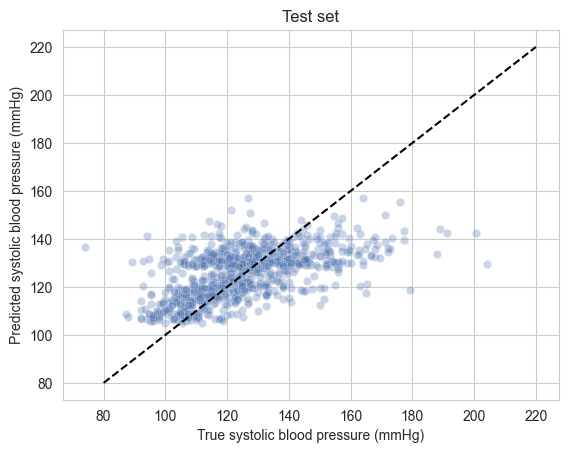

In [25]:
sns.scatterplot(x=test_targets, y=test_predictions, alpha=0.3)
plt.plot([80, 220], [80, 220], "k--")  # diagonal: perfect predictions
plt.xlabel("True systolic blood pressure (mmHg)")
plt.ylabel("Predicted systolic blood pressure (mmHg)")
plt.title("Test set")
plt.show()

*Question: How does the test performance compare to the cross-validated and validation performance of the best model? What does that tell you?*

*Answer: The test R² (0.31) is the same as the validation R² of the best model (0.31), and somewhat higher than its cross-validated R² (0.26). Such differences are expected: as we saw in section 4, the score varies with the random sample of participants in a set (between 0.20 and 0.31 for the linear model). The test score does not suggest that we overfit while selecting the model.*

### Saving the model

A trained model can be saved to a file and loaded again later, for instance to make predictions for new participants without retraining. Because we saved the full pipeline, the scaler is saved along with the model, so new data are automatically scaled in the same way as the training data. Scikit-learn recommends the [`joblib`](https://joblib.readthedocs.io/) library for this, as explained in the [Model persistence](https://scikit-learn.org/stable/model_persistence.html) section of the User Guide. Note that in Google Colab, saved files are removed when the session ends, unless you download them.

In [26]:
import joblib

# Save the model to a file
joblib.dump(best_model, "blood_pressure_model.joblib")

# Load the model again and use it to make predictions
loaded_model = joblib.load("blood_pressure_model.joblib")
loaded_model.predict(test_features.head())

array([135.42083102, 126.3950831 , 113.78185973, 131.16027292,
       129.28240675])

### How good is our final model?

Let's be honest about the result. After exploring the data, comparing models, and tuning hyperparameters, the best model (a random forest) is only slightly better than the linear regression we started with: a cross-validated R² of 0.26 versus 0.25, a difference smaller than the variation between the cross-validation folds. On the test set, the model explains about 30% of the variation in blood pressure, with a typical error of about 12 mmHg.

This is not because we chose the wrong model, but because the task is hard to predict from the available data. Blood pressure depends on many factors that are not in our table, such as genetics, salt intake, stress, and medication, and it even varies from moment to moment within the same person. No model, however complex, can create information that is not in the features. A more complex model only made it easier to overfit.

In practice, an error of more than 10 mmHg is far too large to replace an actual blood pressure measurement: the difference between a normal and a high blood pressure is about 10 to 20 mmHg. At most, such a model could help to flag people who are more likely to have a high blood pressure, so that they can get it measured. To truly improve the predictions, we would need more informative data, not a more complex model.

This is a common outcome in real-life machine learning. Reporting it honestly, including the comparison with a simple baseline, is just as important as getting a good score.

## Summary

In this notebook, we went through a complete machine learning workflow on real-life data. You can use these steps as a checklist for your project:

1. **Explore the data:** understand the task, the columns and the samples. Decide which column is the target, which columns are features, and which columns must be removed (identifiers and leaky columns). Check the data types, special codes, missing values, and the distributions of the features and the target.
2. **Prepare the data:** select the usable samples and the feature and target columns, and split the data into a training, validation, and test set.
3. **Start simple:** train a simple model in a pipeline and evaluate it on the validation set. Compare the training and validation scores to detect overfitting.
4. **Find the best model:** compare models and hyperparameters with a grid search, using cross-validation on the training set. Check the selected model on the validation set.
5. **Evaluate and save:** evaluate the final model once on the test set, compare it with your simple baseline, report the results honestly, and save the model for later use.